In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
data=pd.read_excel("ABC Company.xlsx")
data.head(5)

,Name,Team,Number,Position,Age,Height,Weight,College,Salary
0,Avery Bradley,Boston Celtics,0,PG,25,2023-02-06 00:00:00,180,Texas,7730337.0
1,Jae Crowder,Boston Celtics,99,SF,25,2023-06-06 00:00:00,235,Marquette,6796117.0
2,John Holland,Boston Celtics,30,SG,27,2023-05-06 00:00:00,205,Boston University,NaN
3,R.J. Hunter,Boston Celtics,28,SG,22,2023-05-06 00:00:00,185,Georgia State,1148640.0
4,Jonas Jerebko,Boston Celtics,8,PF,29,2023-10-06 00:00:00,231,NaN,5000000.0


Data Preprocessing:

In [4]:
data["Height"]=np.random.randint(150,180,size=len(data))
print(data.head(5))
print(data["Height"].describe())

            Name            Team  Number Position  Age  Height  Weight  \
0  Avery Bradley  Boston Celtics       0       PG   25     171     180   
1    Jae Crowder  Boston Celtics      99       SF   25     152     235   
2   John Holland  Boston Celtics      30       SG   27     153     205   
3    R.J. Hunter  Boston Celtics      28       SG   22     175     185   
4  Jonas Jerebko  Boston Celtics       8       PF   29     151     231   

             College     Salary  
0              Texas  7730337.0  
1          Marquette  6796117.0  
2  Boston University        NaN  
3      Georgia State  1148640.0  
4                NaN  5000000.0  
count    458.000000
mean     163.665939
std        8.482946
min      150.000000
25%      156.000000
50%      163.000000
75%      171.000000
max      179.000000
Name: Height, dtype: float64


In [8]:
print(data.isnull().sum())
print("Duplicates: ",data.duplicated().sum())

Name          0
Team          0
Number        0
Position      0
Age           0
Height        0
Weight        0
College      84
Salary       11
Age_Group     2
dtype: int64
Duplicates:  0


In [9]:
data.head(5)

,Name,Team,Number,Position,Age,Height,Weight,College,Salary,Age_Group
0,Avery Bradley,Boston Celtics,0,PG,25,171,180,Texas,7730337.0,26-30
1,Jae Crowder,Boston Celtics,99,SF,25,152,235,Marquette,6796117.0,26-30
2,John Holland,Boston Celtics,30,SG,27,153,205,Boston University,NaN,26-30
3,R.J. Hunter,Boston Celtics,28,SG,22,175,185,Georgia State,1148640.0,20-25
4,Jonas Jerebko,Boston Celtics,8,PF,29,151,231,NaN,5000000.0,26-30


Data Analysis Tasks:

In [10]:
d1=data["Team"].value_counts()   #1
d1

Team
New Orleans Pelicans      19
Memphis Grizzlies         18
New York Knicks           16
Milwaukee Bucks           16
Utah Jazz                 16
Boston Celtics            15
Brooklyn Nets             15
Philadelphia 76ers        15
Toronto Raptors           15
Golden State Warriors     15
Los Angeles Clippers      15
Los Angeles Lakers        15
Phoenix Suns              15
Sacramento Kings          15
Chicago Bulls             15
Cleveland Cavaliers       15
Detroit Pistons           15
Indiana Pacers            15
Dallas Mavericks          15
Houston Rockets           15
San Antonio Spurs         15
Atlanta Hawks             15
Charlotte Hornets         15
Miami Heat                15
Washington Wizards        15
Denver Nuggets            15
Oklahoma City Thunder     15
Portland Trail Blazers    15
Orlando Magic             14
Minnesota Timberwolves    14
Name: count, dtype: int64

In [11]:
perc=(data["Team"].value_counts()*100/458).round(2)
perc

Team
New Orleans Pelicans      4.15
Memphis Grizzlies         3.93
New York Knicks           3.49
Milwaukee Bucks           3.49
Utah Jazz                 3.49
Boston Celtics            3.28
Brooklyn Nets             3.28
Philadelphia 76ers        3.28
Toronto Raptors           3.28
Golden State Warriors     3.28
Los Angeles Clippers      3.28
Los Angeles Lakers        3.28
Phoenix Suns              3.28
Sacramento Kings          3.28
Chicago Bulls             3.28
Cleveland Cavaliers       3.28
Detroit Pistons           3.28
Indiana Pacers            3.28
Dallas Mavericks          3.28
Houston Rockets           3.28
San Antonio Spurs         3.28
Atlanta Hawks             3.28
Charlotte Hornets         3.28
Miami Heat                3.28
Washington Wizards        3.28
Denver Nuggets            3.28
Oklahoma City Thunder     3.28
Portland Trail Blazers    3.28
Orlando Magic             3.06
Minnesota Timberwolves    3.06
Name: count, dtype: float64

Text(0.5, 1.0, 'Distribution of employees across each team')

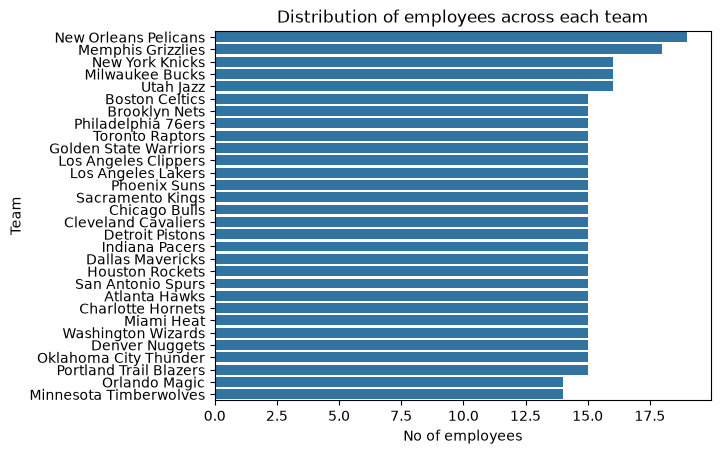

In [12]:
sns.barplot(x=d1.values,y=d1.index)
plt.xlabel("No of employees")
plt.title("Distribution of employees across each team")

In [13]:
d2=data.groupby('Position')['Name'].count()   #2
print(d2)

Position
C      79
PF    100
PG     92
SF     85
SG    102
Name: Name, dtype: int64


Text(0.5, 1.0, 'Employees based on their positions')

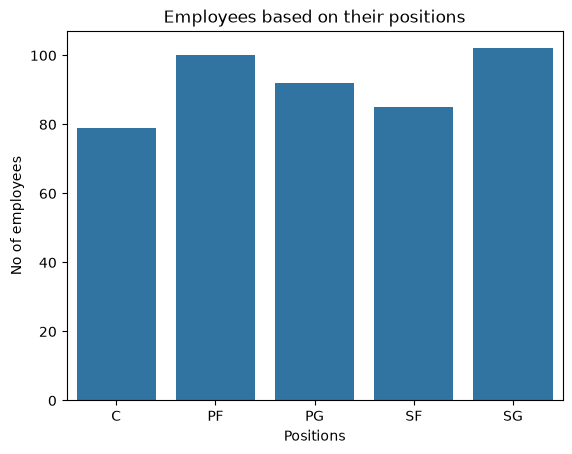

In [14]:
sns.barplot(x=d2.index,y=d2.values)
plt.xlabel("Positions")
plt.ylabel("No of employees")
plt.title("Employees based on their positions")

In [15]:
bins = [20, 25, 30, 35, 40, 50]
labels = ['20-25', '26-30', '31-35', '36-40', '41+']
data['Age_Group'] = pd.cut(data['Age'], bins=bins, labels=labels, right=False)
age_group=data['Age_Group'].value_counts()
print("Age group wise salary:",age_group)

Age group wise salary: Age_Group
26-30    182
20-25    152
31-35     90
36-40     29
41+        3
Name: count, dtype: int64


Text(0.5, 1.0, 'Age Group')

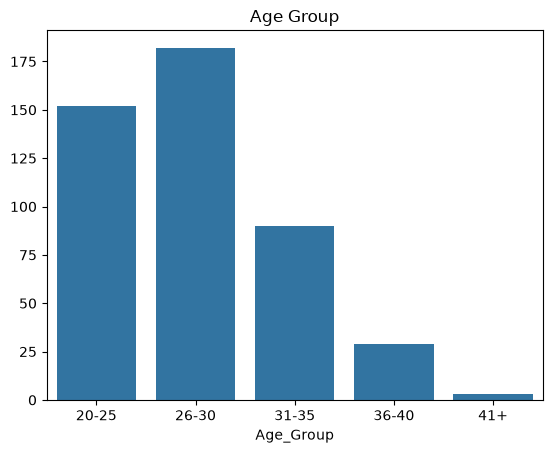

In [20]:
sns.barplot(x=age_group.index,y=age_group.values)
plt.title("Age Group")

Highest salary expenditure of Teams:
 Team
Cleveland Cavaliers    7.642049e+06
Name: Salary, dtype: float64


Text(0.5, 0, 'Salary')

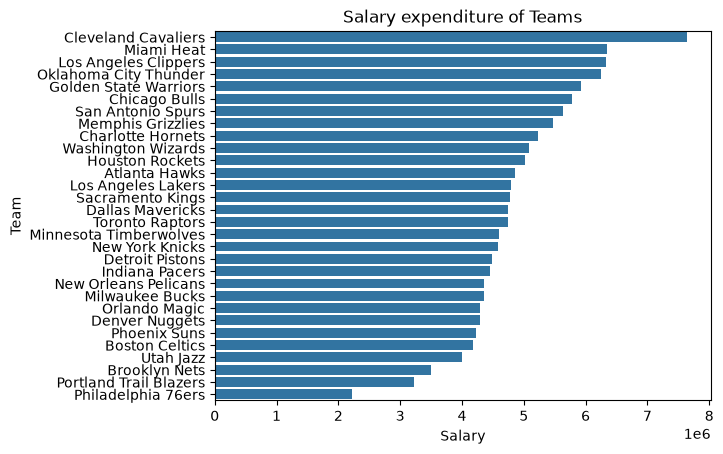

In [88]:
d4=data.groupby('Team')['Salary'].mean().sort_values(ascending=False)    #4
print("Highest salary expenditure of Teams:\n",d4[0:1])
sns.barplot(x=d4.values,y=d4.index)
plt.title("Salary expenditure of Teams")
plt.xlabel("Salary")

Highest salary expenditure of Positions:
 Position
C    5.903511e+06
Name: Salary, dtype: float64


Text(0, 0.5, 'Salary')

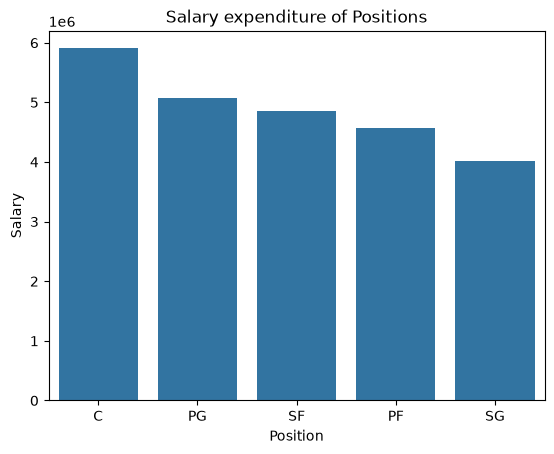

In [91]:
d5=data.groupby('Position')['Salary'].mean().sort_values(ascending=False)
print("Highest salary expenditure of Positions:\n",d5[0:1])
sns.barplot(x=d5.index,y=d5.values)
plt.title("Salary expenditure of Positions")
plt.ylabel('Salary')

             Age    Salary
Age     1.000000  0.214009
Salary  0.214009  1.000000


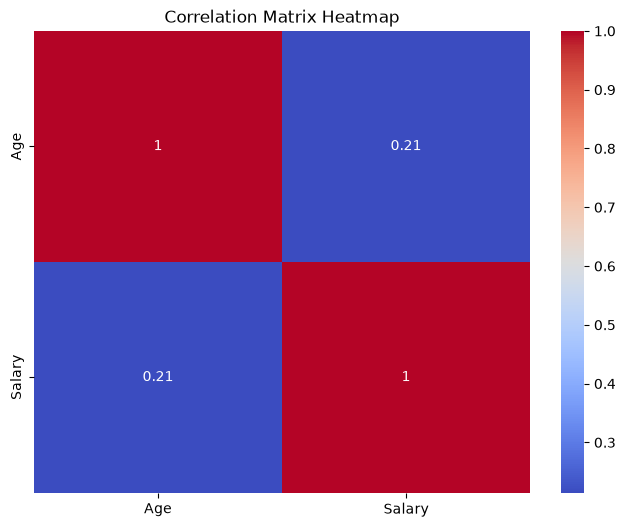

In [87]:
corr_matrix=data[['Age','Salary']].corr()     #5
print(corr_matrix)
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True,cmap='coolwarm')
plt.title("Correlation Matrix Heatmap")
plt.show()

Data Story:

A young and energetic workforce of 458 employees, mostly in their late 20s and early 30s, forming an agile and growth-driven talent pool with higher compensation.

Staff are spread across various specialized teams, with a solid operational base supported by a balanced mix of mid-level contributors and leaders.

Salary budgets naturally follow the largest teams and most senior roles.

Age have nothing to do with the compensation the employees receive.Compensation is driven by role, responsibility, and specialization rather than how long someone has been around.